[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/language_models/10_diffusion_lm.ipynb)

# LM 10 — A masked diffusion language model

*Companion to Lecture 10 — Denoising Diffusion Models.*

Every language model in this track generates text **left to right**, one token per network
evaluation. Diffusion offers a different deal: start from a completely corrupted sequence and
**denoise all positions in parallel**, a few tokens at a time, in any order. For discrete tokens
the natural corruption is not Gaussian noise but **masking**: each token is independently replaced
by a `[MASK]` symbol. The resulting **masked (absorbing-state) diffusion model** (Austin et al., 2021;
Sahoo et al., 2024; Shi et al., 2024) is trained like BERT with a random masking rate, has a proper
likelihood bound, and is the idea behind recent diffusion LLMs such as LLaDA (Nie et al., 2025).
We build one for names, sample from it in two ways, and use it for something an autoregressive
model cannot do directly: **filling in the middle**.

> **Language-model track:** 1 Bigram · 2 MLP LM · 3 Training dynamics · 4 PyTorch · 5 Word-level & regularisation · 6 WaveNet · 7 Char-RNN · 8 GPT · 9 Sequence VAE · **10 Diffusion LM**

**Plan.** (1) data and the masking forward process; (2) the reverse process and the ELBO, which turns out
to be a $1/t$-weighted masked-LM loss; (3) a tiny bidirectional Transformer, trained on CPU;
(4) the likelihood bound; (5) two samplers and their trajectories; (6) sample quality vs the number of
denoising steps; (7) infilling; and a recap of the whole track.

In [1]:
import math
import random
import time
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.grid"] = True
print("device:", device, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cpu


In [2]:
from pathlib import Path
import urllib.request

def load_text(name):
    """Load a corpus from ../data (repository checkout) or download it (e.g. on Colab)."""
    for folder in (Path("data"), Path("../data")):
        if (folder / name).exists():
            return (folder / name).read_text(encoding="utf-8")
    url = f"https://raw.githubusercontent.com/shuishen112/neural-networks/main/data/{name}"
    return urllib.request.urlopen(url).read().decode("utf-8")

## 1. Data: names as fixed-length strings, plus a `[MASK]` token

Standard split and vocabulary of the track (`"."` = 0, `a`–`z` = 1–26). A diffusion model denoises a
whole sequence at once, so, as in LM 9, every name is a row of fixed width $L=16$: the letters followed by
`"."` up to the end. Here the padding is **part of the data**: the model must also predict where the name
ends, and there is no padding mask anywhere. We add one extra input symbol, `[MASK]` = 27, which the
model can read but never has to predict (its output layer has only the 27 real tokens).

In [3]:
words = [w.strip() for w in load_text("names.txt").splitlines() if w.strip()]
random.Random(42).shuffle(words)
n1, n2 = int(0.8 * len(words)), int(0.9 * len(words))
train_words, val_words, test_words = words[:n1], words[n1:n2], words[n2:]

chars = sorted(set("".join(words)))
stoi = {c: i + 1 for i, c in enumerate(chars)}
stoi["."] = 0
itos = {i: c for c, i in stoi.items()}
V = len(stoi)          # 27 real tokens
MASK = V               # 27: the absorbing state, input-only
L = 16
assert V == 27 and itos[0] == "." and itos[26] == "z"
assert max(len(w) for w in words) < L

def encode(w):
    return [stoi[c] for c in w] + [0] * (L - len(w))

def to_name(ids):
    return "".join(itos[i] for i in ids).split(".")[0]

def show(ids):
    """Render a row of token ids, with '_' for [MASK]."""
    return "".join("_" if i == MASK else itos[i] for i in ids)

def to_tensor(ws):
    return torch.tensor([encode(w) for w in ws], dtype=torch.long, device=device)

Xtr, Xva, Xte = to_tensor(train_words), to_tensor(val_words), to_tensor(test_words)
assert all(to_name(encode(w)) == w for w in words)
assert Xtr.shape == (len(train_words), L) and Xtr.dtype == torch.long
train_set = set(train_words)

def n_tokens(X):
    """Letters + one end token per name: the denominator used by every notebook of the track."""
    return int((X != 0).sum().item() + X.shape[0])

print(f"{len(train_words)} train / {len(val_words)} val / {len(test_words)} test names")
print(show(Xtr[0].tolist()), "->", to_name(Xtr[0].tolist()))

25626 train / 3203 val / 3204 test names
yuheng.......... -> yuheng


### 1.1 The forward process: masking instead of Gaussian noise

In Lecture 10 the forward process blended the data with Gaussian noise,
$\mathbf x_t=\sqrt{\bar\alpha_t}\,\mathbf x_0+\sqrt{1-\bar\alpha_t}\,\boldsymbol\epsilon$. Tokens are discrete, so there is
nothing to add noise *to*. The **absorbing-state** process instead keeps each token with probability
$\alpha_t$ and otherwise replaces it by `[MASK]`, independently over positions. In continuous time
$t\in[0,1]$ with the linear schedule $\alpha_t=1-t$:

$$q(x_t^i\mid x_0^i)=\begin{cases}\alpha_t=1-t & x_t^i=x_0^i\\ 1-\alpha_t=t & x_t^i=\texttt{[MASK]}\end{cases}
\qquad\text{independently for } i=1,\dots,L.$$

At $t=0$ we have the data, at $t=1$ every position is masked: the "pure noise" distribution is a single,
known sequence, so there is no prior to match. Once masked, a token stays masked (the state is
*absorbing*), so the forward process from $s$ to $t>s$ only ever *adds* masks.

| | Gaussian diffusion (Lecture 10) | Masked diffusion (here) |
|---|---|---|
| state space | $\mathbb R^d$ | $\{0,\dots,26\}^L$ plus `[MASK]` |
| corruption | shrink + add noise | replace by `[MASK]` |
| $t=1$ | $\mathcal N(\mathbf 0, I)$ | all `[MASK]` |
| network predicts | the noise $\boldsymbol\epsilon$ | the clean tokens $x_0^i$ (a softmax) |
| loss | MSE on $\boldsymbol\epsilon$ | cross-entropy on masked positions, weighted by $1/t$ |
| one reverse step | denoise every coordinate a little | reveal some masked tokens completely |

In [4]:
def forward_mask(x, t):
    """x: (B, L) long, t: (B,) masking probabilities. Returns x_t and the boolean mask (B, L)."""
    m = torch.rand(x.shape, device=x.device) < t.unsqueeze(1)
    return x.masked_fill(m, MASK), m

torch.manual_seed(0)
x_demo = to_tensor(["sophia", "alexander", "mia"])
for t in [0.0, 0.25, 0.5, 0.75, 1.0]:
    xt, _ = forward_mask(x_demo, torch.full((3,), t, device=device))
    print(f"t = {t:.2f}:  " + "   ".join(show(r) for r in xt.tolist()))

# sanity check of the masking arithmetic: the fraction of masked positions is t
xt, m = forward_mask(Xtr[:4000], torch.full((4000,), 0.3, device=device))
print("masked fraction at t = 0.3:", round(m.float().mean().item(), 3))
assert abs(m.float().mean().item() - 0.3) < 0.02
assert torch.equal(xt[~m], Xtr[:4000][~m]) and bool((xt[m] == MASK).all())

t = 0.00:  sophia..........   alexander.......   mia.............
t = 0.25:  sophia._.___.._.   alexan_er...._._   _ia_....._....__
t = 0.50:  so__ia_______._.   _le__nder._.____   ___.__._._....._
t = 0.75:  __p______.._.___   __________._.__.   __a___.______...
t = 1.00:  ________________   ________________   ________________
masked fraction at t = 0.3: 0.297


## 2. The reverse process and the training objective

**The true reverse step.** Take $0\le s<t\le1$. Given the clean token $x_0^i$, Bayes' rule on the forward
process gives a very simple posterior:

* if $x_t^i$ is *not* masked, then $x_s^i=x_t^i$ (tokens are never "re-noised" in reverse);
* if $x_t^i$ is masked, then

$$q(x_s^i\mid x_t^i=\texttt{[MASK]},x_0^i)=\begin{cases}\dfrac{\alpha_s-\alpha_t}{1-\alpha_t}=\dfrac{t-s}{t} & x_s^i=x_0^i \quad\text{(revealed)}\\[2mm] \dfrac{1-\alpha_s}{1-\alpha_t}=\dfrac{s}{t} & x_s^i=\texttt{[MASK]}\quad\text{(stays masked)}\end{cases}$$

**The model** does not know $x_0$, so it uses a network $\mathbf x_\theta(\mathbf x_t)$ that outputs, for every
position, a distribution over the 27 real tokens, and plugs it in for $x_0^i$: a masked token stays masked
with probability $s/t$ and becomes token $v$ with probability $\frac{t-s}{t}\,\mathbf x_\theta^i(\mathbf x_t)[v]$.
This is the analogue of Lecture 10's "predict $\mathbf x_0$ (or $\boldsymbol\epsilon$), then plug it into the Gaussian posterior".

**The ELBO.** As in Lecture 10, the negative ELBO is a sum of KL divergences between true and model reverse
steps. For one masked position both distributions put mass $s/t$ on `[MASK]`; they differ only in how the
remaining mass $\frac{t-s}{t}$ is spread over tokens, so

$$\mathrm{KL}\big(q(x_s^i\mid x_t^i,x_0^i)\,\big\Vert\,p_\theta(x_s^i\mid\mathbf x_t)\big)=\frac{t-s}{t}\,\Big(-\log \mathbf x_\theta^i(\mathbf x_t)[x_0^i]\Big),$$

and it is $0$ for unmasked positions. Summing over $T$ steps of size $\Delta=1/T$ gives
$\sum_k \frac{\Delta}{t_k}\,\mathbb E\big[\sum_{i\text{ masked}}-\log\mathbf x^i_\theta(\mathbf x_{t_k})[x_0^i]\big]$, a Riemann sum. In the limit
$T\to\infty$ (which can be shown to give the tightest bound) we get the **continuous-time ELBO** of MDLM / MD4:

$$\boxed{\;-\log p_\theta(\mathbf x_0)\;\le\;\mathbb E_{t\sim\mathcal U(0,1)}\;\mathbb E_{\mathbf x_t\sim q(\cdot\mid\mathbf x_0)}\Big[\frac1t\sum_{i:\,x_t^i=\texttt{[MASK]}}-\log \mathbf x_\theta^i(\mathbf x_t)[x_0^i]\Big]\;}$$

(The usual boundary terms vanish: $\mathbf x_1$ is all-mask with probability one, so the prior term is $0$, and at
$t=0$ nothing is masked.) In words: **mask a random fraction $t$ of the tokens, predict them with cross-entropy,
and weight by $1/t$**. That is BERT's masked-language-model loss with a random masking rate, and the $1/t$
weight is exactly what turns it into a likelihood bound: at small $t$ only a few tokens are masked (each is
easy and counts a lot), at $t=1$ all $L$ tokens are masked with weight $1$. Note
$\mathbb E[\#\text{masked}]/t=L$ for every $t$: on average every position contributes once.

**Why the network does not need to know $t$.** In Lecture 10 the denoiser had to be told the noise level.
Here, given $\mathbf x_t$, *which* positions are masked is visible, and the probability of the masking pattern,
$t^{\#\text{masked}}(1-t)^{\#\text{unmasked}}$, does not depend on the hidden token values. So the posterior over
the clean tokens is

$$p(\mathbf x_0\mid\mathbf x_t,t)\;\propto\;p_{\text{data}}(\mathbf x_0)\;\mathbb 1\big[\mathbf x_0\text{ agrees with }\mathbf x_t\text{ on the unmasked positions}\big],$$

which is **independent of $t$**. The optimal denoiser is a function of $\mathbf x_t$ alone, so MDLM and LLaDA drop
the time embedding entirely, and so do we.

**Avoiding $1/0$.** We sample $t\sim\mathcal U(\varepsilon,1)$ with $\varepsilon=10^{-3}$; the neglected
interval $[0,\varepsilon)$ changes the bound by $O(\varepsilon)$ nats. To reduce the variance of the
Monte-Carlo estimate we use **stratified** ("low-discrepancy") times within a batch, $t_b=\varepsilon+(1-\varepsilon)\big((u+b/B)\bmod 1\big)$
with one shared $u\sim\mathcal U(0,1)$, so every batch covers the whole range of masking rates.

In [5]:
EPS = 1e-3

def sample_t(B):
    """Stratified times in [EPS, 1], shape (B,), float32."""
    u = (torch.rand(1, device=device) + torch.arange(B, device=device) / B) % 1.0
    return EPS + (1 - EPS) * u

def masked_nelbo(model, x, t):
    """Per-sequence negative-ELBO estimate (nats per name, all L positions); also the CE matrix and mask."""
    xt, m = forward_mask(x, t)
    logits = model(xt)                                                        # (B, L, V)
    ce = F.cross_entropy(logits.reshape(-1, V), x.reshape(-1), reduction="none").view(x.shape)
    return (ce * m).sum(1) / t, ce, m

t_check = sample_t(8)
print("stratified t:", np.round(t_check.cpu().numpy(), 3))
assert t_check.shape == (8,) and float(t_check.min()) >= EPS and float(t_check.max()) <= 1.0

stratified t: [0.268 0.393 0.518 0.642 0.767 0.892 0.018 0.143]


## 3. The denoiser: a bidirectional Transformer

The network maps a partially masked sequence to 27 logits per position. Unlike GPT (LM 8) it uses **no causal
mask**: every position attends to every other one, in both directions, because the unmasked context can be
anywhere. It is a pre-norm Transformer encoder (Lecture 8 §6) built from `nn.TransformerEncoderLayer`, with
learned position embeddings and no time input. We also pass **no padding mask**: the `"."` tokens are data.

In [6]:
class DiffusionLM(nn.Module):
    def __init__(self, d=64, n_layers=3, n_heads=4, d_ff=192):
        super().__init__()
        self.tok = nn.Embedding(V + 1, d)                        # 27 tokens + [MASK]
        self.pos = nn.Parameter(0.02 * torch.randn(1, L, d))
        layer = nn.TransformerEncoderLayer(d, n_heads, dim_feedforward=d_ff, dropout=0.0,
                                           activation="gelu", batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(layer, n_layers, enable_nested_tensor=False)
        self.ln = nn.LayerNorm(d)
        self.head = nn.Linear(d, V)                              # predicts real tokens only

    def forward(self, x):                                        # x: (B, L) long in 0..27
        h = self.tok(x) + self.pos[:, : x.shape[1]]
        h = self.blocks(h)                                       # bidirectional: no attention mask at all
        return self.head(self.ln(h))                             # (B, L, V)

torch.manual_seed(0)
model = DiffusionLM().to(device)
print(f"{sum(p.numel() for p in model.parameters())} parameters")
with torch.no_grad():
    out = model(forward_mask(Xtr[:4], sample_t(4))[0])
print("logits:", tuple(out.shape))
assert out.shape == (4, L, V)

129883 parameters
logits: (4, 16, 27)


**Training** is the boxed objective, averaged over a batch: sample names, a stratified $t$ per name, mask,
predict, cross-entropy on the masked positions, weight by $1/t$. We divide by $L$ only to report a
per-position number; the gradient direction is unchanged. AdamW with a one-cycle learning-rate schedule,
gradient clipping, a fixed number of steps.

step     0  train 3.818 nats/position   val bound 8.335 nats/char   (0 s)


step   250  train 1.176 nats/position   val bound 2.621 nats/char   (6 s)


step   500  train 1.123 nats/position   val bound 2.476 nats/char   (11 s)


step   750  train 1.080 nats/position   val bound 2.415 nats/char   (17 s)


step  1000  train 1.070 nats/position   val bound 2.378 nats/char   (23 s)


step  1250  train 1.026 nats/position   val bound 2.338 nats/char   (28 s)


step  1499  train 1.038 nats/position   val bound 2.334 nats/char   (34 s)


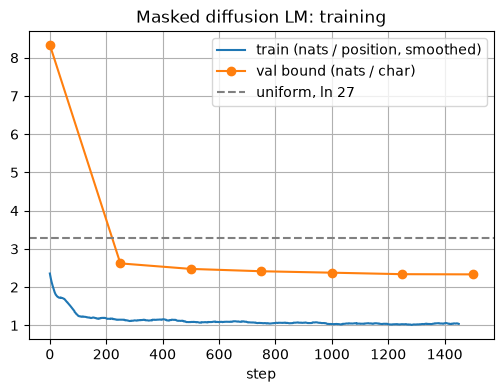

In [7]:
STEPS, BATCH = 1500, 192
opt = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=0.01)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=2e-3, total_steps=STEPS, pct_start=0.1)
gen = torch.Generator().manual_seed(0)

@torch.no_grad()
def quick_val(model, n=2048, seed=1):
    torch.manual_seed(seed)
    x = Xva[:n]
    nelbo, _, _ = masked_nelbo(model, x, sample_t(len(x)))
    return nelbo.sum().item() / n_tokens(x)

losses, val_curve = [], []
t0 = time.time()
for step in range(STEPS):
    model.train()
    idx = torch.randint(0, len(Xtr), (BATCH,), generator=gen).to(device)
    nelbo, _, _ = masked_nelbo(model, Xtr[idx], sample_t(BATCH))
    loss = nelbo.mean() / L
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    opt.step()
    sched.step()
    losses.append(loss.item())
    if step % 250 == 0 or step == STEPS - 1:
        model.eval()
        val_curve.append((step, quick_val(model)))
        print(f"step {step:5d}  train {np.mean(losses[-50:]):.3f} nats/position   "
              f"val bound {val_curve[-1][1]:.3f} nats/char   ({time.time() - t0:.0f} s)")
model.eval()

w = 50
plt.plot(np.convolve(losses, np.ones(w) / w, mode="valid"), label="train (nats / position, smoothed)")
plt.plot(*zip(*val_curve), "o-", label="val bound (nats / char)")
plt.axhline(math.log(V), color="gray", ls="--", label="uniform, ln 27")
plt.xlabel("step"); plt.legend(); plt.title("Masked diffusion LM: training"); plt.show()

The training curve is noisy even with stratified $t$: every step sees a different mix of masking rates. Note
the two curves have different units: "per position" divides by all $L=16$ positions (many of them easy
`"."`s), "per char" divides by the $n+1$ letters and end token of each name, like the rest of the track.

## 4. The likelihood bound

A model of padded strings is also a model of names: each name corresponds to exactly one padded string
(strings like `ab.c....` correspond to no name, so any probability the model gives them is simply lost),
hence $-\log p_\theta(\text{padded name})\ge-\log p_\theta(\text{name})$ under the induced distribution. We
estimate the boxed bound on the whole validation set with several independent draws of $(t,\text{mask})$
per name and divide by the track's token count (letters + end token).

We also look *inside* the bound: the average cross-entropy per masked token as a function of the masking
rate $t$. This is the denoising difficulty curve of the model.

val negative ELBO: 2.323 nats/char   (1 s)


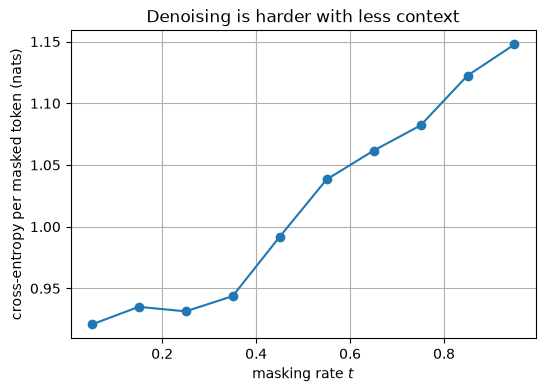

In [8]:
@torch.no_grad()
def diffusion_bound(model, X, repeats=8, seed=0, chunk=1024):
    torch.manual_seed(seed)
    N, total, ts, ce_masked = len(X), 0.0, [], []
    for _ in range(repeats):
        t_all = sample_t(N)[torch.randperm(N, device=device)]
        for i in range(0, N, chunk):
            x, t = X[i:i + chunk], t_all[i:i + chunk]
            nelbo, ce, m = masked_nelbo(model, x, t)
            total += nelbo.sum().item()
            cnt = m.sum(1)
            keep = cnt > 0
            ts.append(t[keep].cpu().numpy())
            ce_masked.append(((ce * m).sum(1)[keep] / cnt[keep]).cpu().numpy())
    return total / (repeats * n_tokens(X)), np.concatenate(ts), np.concatenate(ce_masked)

t0 = time.time()
val_bound, ts, cem = diffusion_bound(model, Xva)
print(f"val negative ELBO: {val_bound:.3f} nats/char   ({time.time() - t0:.0f} s)")
assert math.isfinite(val_bound) and val_bound < 2 * math.log(27)

bins = np.linspace(0, 1, 11)
which = np.clip(np.digitize(ts, bins) - 1, 0, 9)
centres = 0.5 * (bins[:-1] + bins[1:])
plt.plot(centres, [cem[which == b].mean() for b in range(10)], "o-")
plt.xlabel("masking rate $t$"); plt.ylabel("cross-entropy per masked token (nats)")
plt.title("Denoising is harder with less context"); plt.show()

At small $t$ almost the whole name is visible and a masked character is easy to guess; at $t\to1$ the model
can only predict position-wise frequencies (the first letter is often `a`, `j`, `m`, ..., late positions are
almost surely `"."`). The ELBO integrates this curve with the weight $1/t \times \mathbb E[\#\text{masked}]$.

This is an **upper bound** on the model's NLL in the track's units. At this scale it is typically *worse* than
the exact NLLs of the autoregressive models of LM 2–8: the masked model has to learn to predict every
position from every subset of the others (a much harder task than left-to-right prediction with the same
parameters and compute), and the ELBO is not tight. Larger studies (MDLM, LLaDA) find that the gap
shrinks with scale but does not vanish.

In [9]:
print(f"val NLL (nats/char): {val_bound:.3f}   (upper bound: continuous-time ELBO of the masked diffusion model)")

val NLL (nats/char): 2.323   (upper bound: continuous-time ELBO of the masked diffusion model)


## 5. Sampling: from all-`[MASK]` to a name

Generation runs the reverse process: start from $\mathbf x_1=$ `[MASK]`$^L$, choose $K$ steps
$1=t_K>t_{K-1}>\dots>t_0=0$ (uniform, $t_k=k/K$), and at each step evaluate the network **once for all
positions**. Two ways to decide what to reveal:

**(a) Ancestral sampling** (the principled one). Exactly the model reverse step of §2: for each masked
position, with probability $(t-s)/t$ reveal it with a token sampled from $\mathbf x_\theta^i(\mathbf x_t)$, otherwise
leave it masked. Already revealed tokens are never changed. At the last step $s=0$, so everything left is
revealed. With $K\to\infty$ this samples exactly from the model; with small $K$ several tokens are revealed
*in the same step* from their **marginal** predictions, independently, which is an approximation (in the
extreme $K=1$ all $L$ tokens are drawn independently from $p(x^i\mid\text{all masked})$).

**(b) Confidence-based remasking** (as in LLaDA, Nie et al., 2025; also MaskGIT for images). At each step,
sample a token for *every* masked position, then keep only the ones the model is most confident about
(highest probability of the sampled token) and re-mask the rest, so that the number of masks follows the
schedule ($\operatorname{round}(s\cdot n_0)$ masks remain after the step, $n_0$ = masks at the start).
This is not the ancestral sampler of the ELBO (it chooses *which* positions to reveal adaptively, easy ones
first), but it often gives better samples at a small $K$.

In [10]:
@torch.no_grad()
def sample_ancestral(model, x_init, K, record=False):
    x = x_init.clone()
    traj = [x.clone()]
    for k in range(K, 0, -1):
        t, s = k / K, (k - 1) / K
        masked = x == MASK
        probs = F.softmax(model(x), dim=-1)                                       # (N, L, V)
        x0 = torch.multinomial(probs.reshape(-1, V), 1).view(x.shape)             # a token for every position
        reveal = masked & (torch.rand(x.shape, device=x.device) < (t - s) / t)
        x = torch.where(reveal, x0, x)
        if record:
            traj.append(x.clone())
    return x, traj

@torch.no_grad()
def sample_confidence(model, x_init, K, record=False):
    x = x_init.clone()
    N = x.shape[0]
    n0 = (x == MASK).sum(1)                                                      # (N,) masks at the start
    positions = torch.arange(L, device=x.device).repeat(N, 1)                   # (N, L)
    traj = [x.clone()]
    for k in range(K, 0, -1):
        s = (k - 1) / K
        masked = x == MASK
        probs = F.softmax(model(x), dim=-1)                                       # (N, L, V)
        x0 = torch.multinomial(probs.reshape(-1, V), 1).view(x.shape)             # (N, L)
        conf = torch.gather(probs, -1, x0.unsqueeze(-1)).squeeze(-1)              # (N, L) prob. of the sampled token
        conf = torch.where(masked, conf, torch.full_like(conf, -1.0))             # never "reveal" a revealed token
        n_keep = torch.round(s * n0.float()).long()                               # masks that remain after this step
        n_reveal = (masked.sum(1) - n_keep).clamp(min=0)                          # (N,)
        order = conf.argsort(dim=1, descending=True)                              # most confident first
        rank = torch.empty_like(order).scatter_(1, order, positions)              # rank[n, i] = rank of position i
        reveal = masked & (rank < n_reveal.unsqueeze(1))
        x = torch.where(reveal, x0, x)
        if record:
            traj.append(x.clone())
    return x, traj

def all_masked(n):
    return torch.full((n, L), MASK, dtype=torch.long, device=device)

torch.manual_seed(0)
for name, sampler in [("ancestral", sample_ancestral), ("confidence", sample_confidence)]:
    xs, _ = sampler(model, all_masked(64), K=16)
    assert not bool((xs == MASK).any())
    print(f"{name:10s} K=16:", " ".join(to_name(r) or "<empty>" for r in xs[:16].tolist()))

ancestral  K=16: atma hayum kecyin somberes vilene lioyn azda ayvulyeha konari jhamea rujceyneel lalleie rajeshah hajaha dusnta ste
confidence K=16: mayah jala myn caie nalee anena partah alaya layna kely jayay anfi sebi lyman maya kos


### 5.1 Watching names appear

The reverse trajectories of six samples, top ($t=1$) to bottom ($t=0$), `_` = `[MASK]`. Ancestral sampling
reveals positions in a random order; confidence-based sampling typically fills the easy positions first (the
trailing `"."`s, then frequent letters) and leaves the hard, informative ones for later.

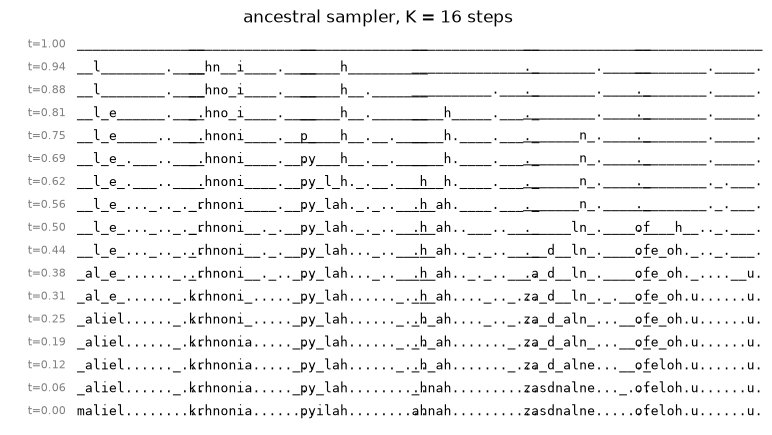

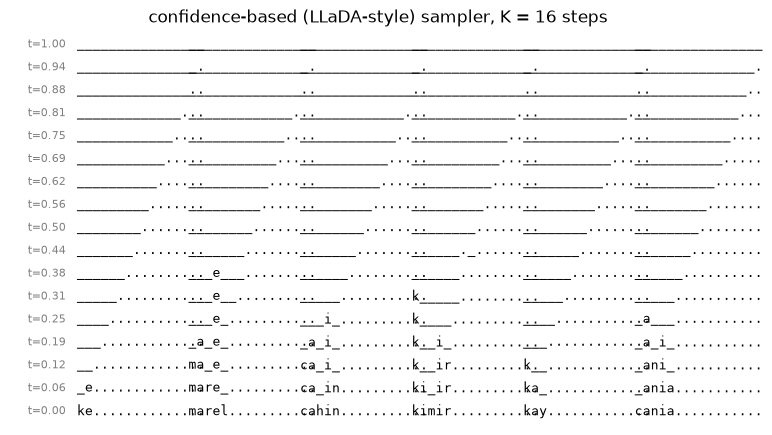

In [11]:
def plot_trajectory(traj, n_show, title):
    K = len(traj) - 1
    fig, ax = plt.subplots(figsize=(1.45 * n_show + 0.8, 0.26 * (K + 1) + 0.7))
    ax.axis("off")
    for r, x in enumerate(traj):
        rows = x[:n_show].tolist()
        ax.text(-0.1, -r, f"t={1 - r / K:.2f}", ha="right", va="center", fontsize=8, color="gray")
        for c in range(n_show):
            ax.text(c, -r, show(rows[c]), family="monospace", fontsize=9, va="center")
    ax.set_xlim(-0.6, n_show); ax.set_ylim(-K - 0.6, 0.6)
    ax.set_title(title)
    plt.show()

torch.manual_seed(3)
_, traj_a = sample_ancestral(model, all_masked(6), K=16, record=True)
plot_trajectory(traj_a, 6, "ancestral sampler, K = 16 steps")
torch.manual_seed(3)
_, traj_c = sample_confidence(model, all_masked(6), K=16, record=True)
plot_trajectory(traj_c, 6, "confidence-based (LLaDA-style) sampler, K = 16 steps")

## 6. Sample quality vs the number of steps $K$

The selling point of diffusion LMs is that $K$ can be smaller than the sequence length: several tokens per
network call. How much quality does that cost? For each $K$ we draw 1000 names and measure

* **valid**: letters followed only by `"."` (no `ab.c...`, not empty);
* **in train / novel**: valid names that do / do not occur in the training set (memorisation vs invention);
* **mean length** of valid names (data: about 6.1);
* **bigram NLL**: the average NLL per character of the valid samples under the bigram model of LM 1 (fitted on
  the training names). It is a crude "how name-like is this" score: real validation names get about 2.45,
  random strings far more.

In [12]:
counts = np.ones((V, V))                                   # bigram counts with add-one smoothing
for w in train_words:
    seq = [0] + [stoi[c] for c in w] + [0]
    for a, b in zip(seq[:-1], seq[1:]):
        counts[a, b] += 1
logP = np.log(counts / counts.sum(1, keepdims=True))

def bigram_nll(names):
    tot, n = 0.0, 0
    for w in names:
        seq = [0] + [stoi[c] for c in w] + [0]
        tot -= sum(logP[a, b] for a, b in zip(seq[:-1], seq[1:]))
        n += len(seq) - 1
    return tot / max(n, 1)

def sample_stats(xs):
    rows = xs.cpu().tolist()
    valid = []
    for r in rows:
        s = "".join(itos[i] for i in r)
        name = s.split(".")[0]
        if 0 < len(name) < L and set(s[len(name):]) == {"."}:
            valid.append(name)
    return {"valid": len(valid) / len(rows),
            "in train": np.mean([n in train_set for n in valid]) if valid else 0.0,
            "novel": np.mean([n not in train_set for n in valid]) if valid else 0.0,
            "mean len": np.mean([len(n) for n in valid]) if valid else float("nan"),
            "bigram NLL": bigram_nll(valid) if valid else float("nan"),
            "names": valid}

print(f"real validation names: bigram NLL {bigram_nll(val_words):.3f}, mean length {np.mean([len(w) for w in val_words]):.2f}")
Ks = [1, 2, 4, 8, 16, 32]
stats = {}
t0 = time.time()
for name, sampler in [("ancestral", sample_ancestral), ("confidence", sample_confidence)]:
    for K in Ks:
        torch.manual_seed(K)
        xs, _ = sampler(model, all_masked(1000), K)
        stats[name, K] = sample_stats(xs)
print(f"({time.time() - t0:.0f} s)\n")
print(f"{'sampler':11s} {'K':>3s} {'valid':>7s} {'in train':>9s} {'novel':>7s} {'mean len':>9s} {'bigram NLL':>11s}")
for (name, K), r in stats.items():
    print(f"{name:11s} {K:3d} {r['valid']:7.1%} {r['in train']:9.1%} {r['novel']:7.1%} {r['mean len']:9.2f} {r['bigram NLL']:11.3f}")

real validation names: bigram NLL 2.453, mean length 6.07


(5 s)

sampler       K   valid  in train   novel  mean len  bigram NLL
ancestral     1   64.7%      0.9%   99.1%      6.10       3.105
ancestral     2   82.8%      3.0%   97.0%      6.07       2.896
ancestral     4   92.2%      4.4%   95.6%      6.18       2.759
ancestral     8   95.0%      4.0%   96.0%      6.12       2.720
ancestral    16   96.5%      4.0%   96.0%      6.12       2.738
ancestral    32   96.7%      3.8%   96.2%      6.18       2.687
confidence    1   64.7%      0.9%   99.1%      6.10       3.105
confidence    2   73.4%      2.5%   97.5%      5.67       3.065
confidence    4   95.0%      7.6%   92.4%      5.21       2.664
confidence    8   98.6%     20.2%   79.8%      4.74       2.403
confidence   16   99.9%     33.9%   66.1%      4.47       2.209
confidence   32  100.0%     39.9%   60.1%      4.44       2.207


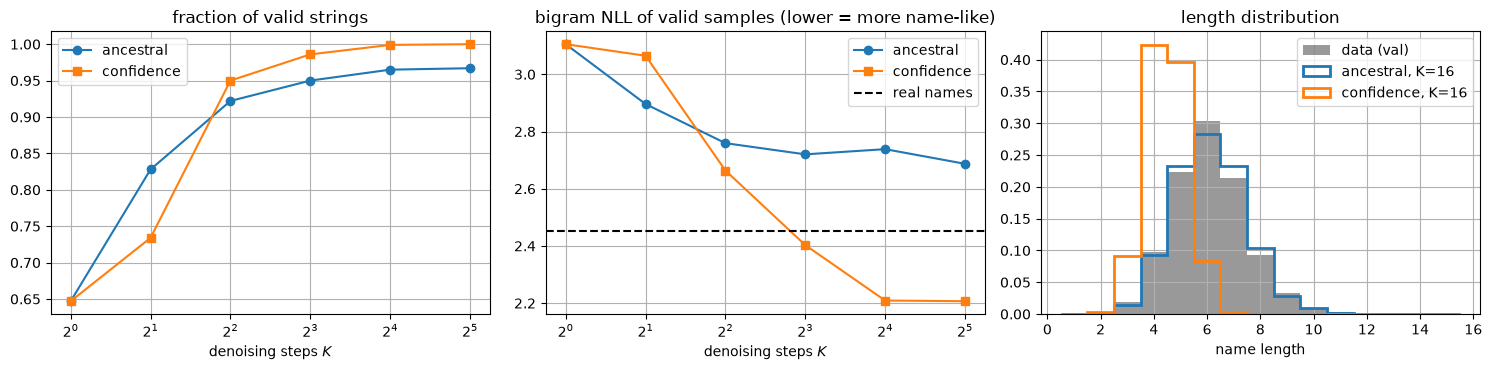

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for name, mk in [("ancestral", "o-"), ("confidence", "s-")]:
    axes[0].plot(Ks, [stats[name, K]["valid"] for K in Ks], mk, label=name)
    axes[1].plot(Ks, [stats[name, K]["bigram NLL"] for K in Ks], mk, label=name)
axes[1].axhline(bigram_nll(val_words), color="k", ls="--", label="real names")
for ax, title in zip(axes[:2], ["fraction of valid strings", "bigram NLL of valid samples (lower = more name-like)"]):
    ax.set_xscale("log", base=2); ax.set_xlabel("denoising steps $K$"); ax.set_title(title); ax.legend()
len_bins = np.arange(1, 17) - 0.5
axes[2].hist([len(w) for w in val_words], bins=len_bins, density=True, alpha=0.4, color="k", label="data (val)")
for name, c in [("ancestral", "C0"), ("confidence", "C1")]:
    axes[2].hist([len(n) for n in stats[name, 16]["names"]], bins=len_bins, density=True,
                 histtype="step", lw=2, color=c, label=f"{name}, K=16")
axes[2].set_xlabel("name length"); axes[2].set_title("length distribution"); axes[2].legend()
plt.tight_layout(); plt.show()

What to look for (exact numbers vary with the seed):

* **$K=1$ is bad.** All 16 tokens are drawn independently from their marginals given an all-mask input, so
  letters and `"."`s are mixed up: few valid strings and un-name-like letter combinations. This is the
  price of parallel decoding: within one step, tokens are sampled **independently** and cannot coordinate.
* **Quality improves quickly with $K$** and saturates around $K\approx L$: once only about one token is revealed
  per step, the sampler is (close to) exact and extra steps are wasted computation. The interesting regime is
  in between, where we trade a little quality for a 2–4× reduction in network calls.
* **Confidence-based sampling** usually stays valid at smaller $K$ (it fixes the easy structure, such as the
  end of the name, first) and tends to produce more frequent, "safer" names (more of them in the training
  set). Like low-temperature sampling, it trades diversity for quality.
* The **length distribution** of good samples should follow the data closely: the model learned where names end.

Compare the cost with an autoregressive model: a name of $n$ letters needs $n+1$ sequential network calls there;
here it needs $K$, independent of the length, but each call processes all $L$ positions and has no KV cache.

## 7. Infilling: what an autoregressive model cannot do directly

An autoregressive model only conditions on a **prefix**. To get names that *end* in `-lyn`, or have a `z`
in third position, it would have to sample many names and reject the ones that do not match. The masked
diffusion model conditions on **any** subset of positions for free: we simply start the reverse process
from a partially masked sequence, with the fixed characters unmasked. Both samplers only ever change masked
positions, so the constraints are satisfied by construction.

Template syntax: letters are fixed, `_` is a blank to fill; the rest of the row is padded with `"."` (so the
length is fixed), unless the template ends with `*`, in which case the rest is left masked (free length).

In [14]:
def template_ids(tpl):
    free_tail = tpl.endswith("*")
    core = tpl.rstrip("*")
    ids = [MASK if c == "_" else stoi[c] for c in core]
    return ids + [MASK if free_tail else 0] * (L - len(ids))

def infill(tpl, n=10, K=16, sampler=sample_confidence, seed=0):
    torch.manual_seed(seed)
    x_init = torch.tensor([template_ids(tpl)] * n, dtype=torch.long, device=device)
    xs, _ = sampler(model, x_init, K)
    fixed = x_init != MASK
    assert torch.equal(xs[fixed], x_init[fixed])            # the given characters are untouched
    assert not bool((xs == MASK).any())
    return [to_name(r) for r in xs.tolist()]

for tpl, what in [("ma____a", "7 letters, starts with 'ma', ends with 'a'"),
                  ("_____lyn", "8 letters ending in '-lyn'"),
                  ("__z*", "third letter 'z', any length"),
                  ("_____", "exactly 5 letters"),
                  ("_r_n___*", "'r' second, 'n' fourth")]:
    names = infill(tpl)
    print(f"{tpl:10s} ({what})\n    " + " ".join(names))
    print(f"    in training set: {np.mean([n in train_set for n in names]):.0%}")

ma____a    (7 letters, starts with 'ma', ends with 'a')
    manissa masrina mallina mankina malcana maliana maryara mayamra marilya maliana
    in training set: 0%
_____lyn   (8 letters ending in '-lyn')
    janhalyn kanlelyn jannilyn qannelyn kantelyn cadellyn jaaellyn kraeelyn denlelyn kamxelyn
    in training set: 0%
__z*       (third letter 'z', any length)
    jazan jazya nazel ayzia jazia razen kaza evza kezai mazel
    in training set: 0%
_____      (exactly 5 letters)
    javia kari jariu rana mayhi maia niaa fari kani kama
    in training set: 50%
_r_n___*   ('r' second, 'n' fourth)
    arina brina brin grana bren brina bryn gran brana aron
    in training set: 40%


Fill-in-the-middle is useful far beyond names: editing a sentence, completing code between existing lines,
constrained generation. Autoregressive LLMs get a version of it by a *data trick* (FIM training: move the
middle of a document to the end, Bavarian et al., 2022), whereas for masked diffusion it is built in.
(A small caveat: if a template is unusual, the model may put a `"."` inside the blanks, producing a shorter name
than intended; the fixed characters are still respected.)

## From here to LLMs

* **Diffusion LLMs exist.** LLaDA (Nie et al., 2025) trains an 8B-parameter masked diffusion model with
  exactly our objective (random masking rate, $1/t$-weighted cross-entropy on masked tokens, bidirectional
  Transformer, no time input) and samples with low-confidence remasking; it reports results competitive with
  autoregressive models of similar size on many benchmarks. Commercial systems such as Inception Labs' Mercury
  and Google's Gemini Diffusion (announced 2025) advertise diffusion-based text and code generation with much
  higher tokens-per-second than comparable autoregressive models. This is recent and fast-moving work; treat
  the specific claims with care.
* **Why the interest: parallel decoding.** An AR model needs one sequential forward pass per token, and at
  inference time is usually limited by memory bandwidth, not arithmetic. A diffusion LM produces many tokens per
  pass, so with $K\ll L$ it can be much faster, and it can revise or fill in any position. Speculative decoding
  and multi-token prediction are attempts to get some of this parallelism into AR models.
* **The trade-offs** we saw in miniature: (i) tokens revealed in the same step are sampled independently,
  so small $K$ costs quality; (ii) the likelihood is only a bound and, at equal compute, usually worse than
  AR; (iii) bidirectional attention means no KV cache, so each step re-processes the whole sequence
  (block-wise "semi-autoregressive" decoding, as in LLaDA and Block Diffusion, recovers some of the caching);
  (iv) a fixed canvas length $L$ must be chosen in advance (here the `"."` padding solved it).
* **BERT was almost a generative model.** BERT's masked-LM objective uses a fixed 15 % masking rate. Make the
  rate random and weight by $1/t$, and the same network becomes a generative model with a likelihood bound.

### The whole track at a glance

| # | Notebook | Model | Key idea | Val NLL (nats/char) |
|---|---|---|---|---|
| 1 | Bigram | counts → softmax regression | maximum likelihood, NLL as the metric | 2.45 (names) |
| 2 | MLP LM | Bengio et al. (2003) MLP, manual backprop | embeddings, a context window | 2.14 (names) |
| 3 | Training dynamics | the same MLP | initialisation, activation statistics, learning rates | 2.11 (names) |
| 4 | PyTorch | the MLP LM in PyTorch | autograd, `nn.Module`, optimisers; context 8 | 2.02 (names) |
| 5 | Word-level & regularisation | word-level LM on Shakespeare | overfitting, dropout, weight decay, tying | 1.23 (Shakespeare, subset, words) |
| 6 | WaveNet | causal dilated convolutions | hierarchical receptive field, all positions at once | 2.01 (names) |
| 7 | Char-RNN | character LSTM on Shakespeare | recurrence, unbounded context | 1.71 (Shakespeare) |
| 8 | GPT | BPE tokeniser + decoder-only Transformer | causal self-attention, the LLM architecture | 1.81 (Shakespeare) |
| 9 | Sequence VAE | GRU encoder → $\mathbf z$ → GRU decoder | ELBO, posterior collapse, latent space | ≤ 2.13 (names, bound) |
| 10 | Diffusion LM | bidirectional Transformer denoiser | masked diffusion, parallel decoding, infilling | ≤ 2.32 (names, bound) |

The numbers are from one CPU run of each notebook with the default settings; every notebook prints its own
`val NLL (nats/char)`, so you can compare with your runs. Numbers on different datasets (names vs Shakespeare) are not comparable,
and LM 5's word-level number was trained on a small subset and converted to nats per character. The arc of the track: **one objective** (maximise the likelihood of the data,
or a bound on it) and a sequence of better function approximators and factorisations. LLMs are the
autoregressive end of that arc scaled up by many orders of magnitude; diffusion LMs are the most serious current
alternative to it.

## Try it yourself

1. **Time conditioning.** Add a sinusoidal embedding of $t$ (Lecture 10) to the input. Does the ELBO improve?
   The argument in §2 says it should not (much).
2. **Drop the $1/t$ weight** and train with plain mean cross-entropy over masked tokens (as BERT does). The
   printed number is then no longer a bound; do the samples get better or worse?
3. **Other schedules.** Use $\alpha_t=\cos(\pi t/2)$; the weight becomes $-\alpha_t'/(1-\alpha_t)$. Re-derive it,
   implement it, and compare the ELBO and sample quality at $K=8$.
4. **Semi-autoregressive decoding.** Split the 16 positions into blocks of 4 and denoise them left to right,
   each block with a few steps (as in LLaDA). How do validity and novelty compare with the samplers above?
5. **More infilling.** Generate names that are palindromes of length 5 (fix positions 1 and 5 to the same
   letter, then 2 and 4, ...). What other constraints can you express, and which ones can you *not* express
   with independent per-position conditioning?

**Further reading.**
Austin, Johnson, Ho, Tarlow & van den Berg, "Structured denoising diffusion models in discrete state-spaces" (D3PM), NeurIPS 2021;
Sahoo et al., "Simple and effective masked diffusion language models" (MDLM), NeurIPS 2024;
Shi, Han, Wang, Doucet & Titsias, "Simplified and generalized masked diffusion for discrete data" (MD4), NeurIPS 2024;
Ou et al., "Your absorbing discrete diffusion secretly models the conditional distributions of clean data", ICLR 2025;
Nie et al., "Large language diffusion models" (LLaDA), 2025;
Chang et al., "MaskGIT: masked generative image transformer", CVPR 2022;
Lou, Meng & Ermon, "Discrete diffusion modeling by estimating the ratios of the data distribution" (SEDD), ICML 2024;
Arriola et al., "Block diffusion: interpolating between autoregressive and diffusion language models", ICLR 2025;
Bavarian et al., "Efficient training of language models to fill in the middle", 2022;
Devlin et al., "BERT", NAACL 2019.